# 01 · Data Preparation & Cleaning
**Duka Electronics · H1 2026 · Phases 2–3 (Prepare, Process)**

**Purpose.** Audit the raw data against the six data-quality dimensions, clean it with the reusable
function in `src/cleaning.py`, record every decision in a cleaning log, and load the clean tables into SQLite.

**Table grain (one row represents...)**

| Table | Grain | Key | Fields used |
|---|---|---|---|
| `orders` | one order line (one product per order) | `order_id` | date, branch, product, quantity, unit price, discount, customer, channel, payment, status |
| `customers` | one customer | `customer_id` → `customer_key` | county, age (banded), signup date |
| `products` | one product | `product_id` | name, category, list price |

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "reports" / "tables"; TAB.mkdir(parents=True, exist_ok=True)
DB = ROOT / "data" / "duka.db"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid.axis": "y"})
BRANCH_COLORS = {"Nairobi": "#1F4E79", "Mombasa": "#C0504D", "Nakuru": "#E39B3B",
                 "Eldoret": "#2E8B57", "Kisumu": "#8C8C8C"}
pd.options.display.float_format = "{:,.1f}".format

def save_fig(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", dpi=150)

## 1. Load raw data
Phone numbers are read as text so leading zeros are not lost.

In [2]:
RAW = ROOT / "data" / "raw"
if not (RAW / "orders_raw.csv").exists():          # regenerate if the raw files are absent
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "data" / "generate_data.py")], check=True)

orders_raw = pd.read_csv(RAW / "orders_raw.csv", dtype={"discount_pct": str})
customers_raw = pd.read_csv(RAW / "customers_raw.csv", dtype={"phone": str})
products_raw = pd.read_csv(RAW / "products_raw.csv")
for name, df in [("orders", orders_raw), ("customers", customers_raw), ("products", products_raw)]:
    print(f"{name:10s} {df.shape[0]:>7,} rows x {df.shape[1]} cols")
orders_raw.head()

orders      15,816 rows x 11 cols
customers    3,040 rows x 7 cols
products        24 rows x 4 cols


,order_id,order_date,branch,product_id,quantity,unit_price,discount_pct,customer_id,channel,payment_method,order_status
0,O010191,2026-03-17,Nairobi,P020,-1,"1,807.0",0,C02992,In-store,Cash,Completed
1,O014203,2026-06-16,Nakuru,P020,2,"1,802.0",15,C00251,In-store,Bank Transfer,Completed
2,O006009,2026-06-07,Nairobi,P017,1,811.0,0,C01992,In-store,M-Pesa,Completed
3,O001035,2026-05-14,Mombasa,P017,2,797.0,0,C02899,In-store,M-Pesa,Completed
4,O007653,2026-04-27,Kisumu,P020,4,"1,811.0",0,C02776,Online,Bank Transfer,Completed


## 2. Six-dimension data-quality audit (raw data)

In [3]:
from cleaning import audit_quality, clean_data
audit = audit_quality(orders_raw, customers_raw, products_raw)
audit

,dimension,table,check,issues,total_rows,pct
0,Completeness,orders,missing customer_id,237,15816,1.5
1,Completeness,orders,missing payment_method,452,15816,2.9
2,Completeness,orders,missing unit_price,157,15816,1.0
3,Completeness,orders,missing channel,93,15816,0.6
4,Completeness,customers,missing age,153,3040,5.0
5,Completeness,customers,missing email,92,3040,3.0
6,Completeness,customers,missing county,60,3040,2.0
7,Completeness,products,missing list_price_kes,1,24,4.2
8,Validity,orders,quantity <= 0 or > 10,77,15816,0.5
9,Validity,orders,unparseable order_date,0,15816,0.0


,checks,checks_with_issues,worst_pct
dimension,,,
Completeness,8,8,5.0
Validity,6,5,0.8
Accuracy,2,1,0.3
Consistency,6,6,10.0
Uniqueness,3,3,2.0
Timeliness,2,1,0.2


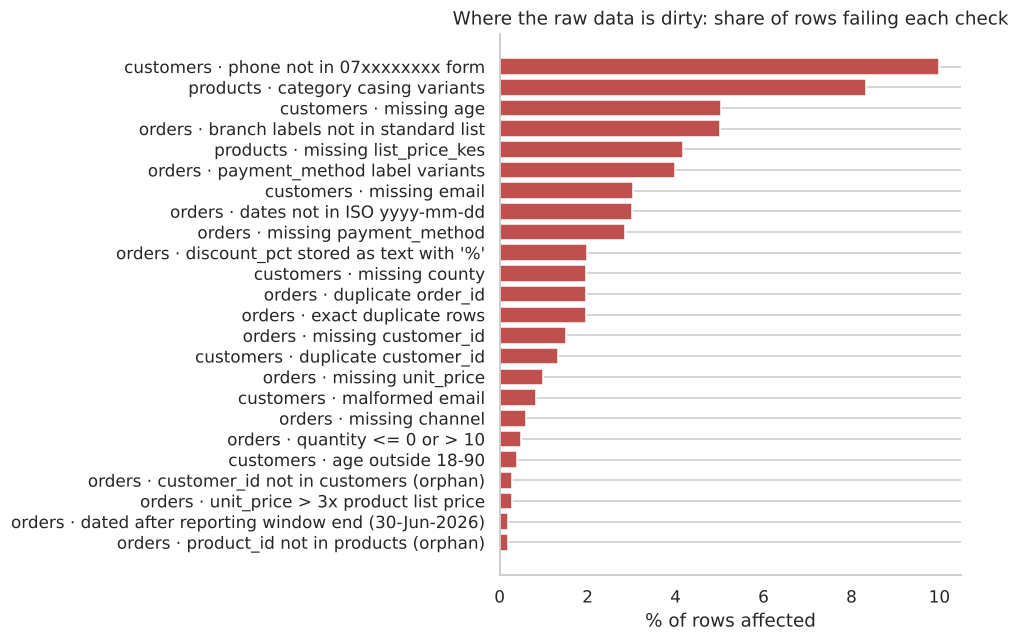

In [4]:
summary = (audit.assign(has_issue=audit["issues"] > 0)
           .groupby("dimension", sort=False)
           .agg(checks=("check", "count"), checks_with_issues=("has_issue", "sum"),
                worst_pct=("pct", "max")))
display(summary)

fig, ax = plt.subplots(figsize=(9, 6))
plot = audit[audit["issues"] > 0].sort_values("pct")
ax.barh(plot["table"] + " · " + plot["check"], plot["pct"], color="#C0504D")
ax.set_xlabel("% of rows affected"); ax.set_title("Where the raw data is dirty: share of rows failing each check")
plt.tight_layout(); save_fig(fig, "01_quality_audit.png"); plt.show()

### Audit reading guide
* **Completeness** – gaps in payment method, customer, price, channel, age, county.
* **Validity** – impossible quantities (-1, 500), impossible ages (0, 150, 999), malformed emails, orphan product/customer keys.
* **Accuracy** – prices ~10× the list price (decimal-slip keying errors).
* **Consistency** – five spellings of branch names, two date formats, `"10%"` stored as text, payment-label variants.
* **Uniqueness** – duplicated order lines and customers.
* **Timeliness** – orders dated in 2027 (impossible for an H1-2026 extract).

> Phone numbers use two formats (`07…` and `+254…`); they are dropped from the clean data anyway (privacy), but the inconsistency is still recorded.

## 3. Clean with the reusable function

In [5]:
tables, log = clean_data(orders_raw, customers_raw, products_raw)
pd.set_option("display.max_colwidth", 90)
log[["table", "step", "issue", "rows_affected", "action", "justification"]]

,table,step,issue,rows_affected,action,justification
0,products,standardise,category casing variants,2,Mapped to canonical category names,Same category must map to one label or group-bys split it.
1,customers,deduplicate,duplicate customer rows,40,"Dropped duplicates, kept first",customer_id is the primary key; duplicates inflate customer counts.
2,customers,validity,"impossible ages (0, 150, 999)",12,Set to missing,"Customers must be adults; values are entry errors, not recoverable."
3,customers,privacy,exact age is quasi-identifying,3000,Replaced age with age_band,Banding reduces re-identification risk (Ethics statement).
4,customers,completeness,missing county,60,Filled with 'Unknown',Keeps the row for analysis; avoids guessing a location.
5,customers,privacy,"direct identifiers (name, phone, email)",3000,"Dropped full_name, phone, email; customer_id replaced by salted SHA-256 key",Analysis needs no direct identifiers; protects individuals under Kenya Data Protection...
6,orders,deduplicate,exact duplicate order lines,310,Dropped duplicates,Duplicates double-count revenue.
7,orders,standardise,branch spelling / case / abbreviations,699,"Trimmed, title-cased, mapped Nbi/Msa/Eld to full names",Otherwise one branch appears as several.
8,orders,standardise,mixed date formats (dd/mm/yyyy),464,"Parsed to datetime (ISO first, then day-first)",Kenyan convention is day-first.
9,orders,timeliness,dates outside Jan-Jun 2026 window,31,Dropped rows,"Future dates are impossible; true date unknown, so cannot be corrected."


### Rows retained

In [6]:
kept = len(tables["orders"]) / len(orders_raw)
print(f"Raw order lines  : {len(orders_raw):,}")
print(f"Clean order lines: {len(tables['orders']):,}  ({kept:.1%} retained)")
print(f"Customers        : {len(customers_raw):,} -> {len(tables['customers']):,}")
print(f"Products         : {len(products_raw)} -> {len(tables['products'])}")

Raw order lines  : 15,816
Clean order lines: 15,367  (97.2% retained)
Customers        : 3,040 -> 3,000
Products         : 24 -> 24


## 4. Post-clean validation (assertions)

In [7]:
o, c, p = tables["orders"], tables["customers"], tables["products"]
assert o["order_id"].is_unique, "duplicate order_id"
assert set(o["branch"]) == {"Nairobi", "Mombasa", "Kisumu", "Nakuru", "Eldoret"}
assert o["quantity"].between(1, 10).all()
assert o["order_date"].between("2026-01-01", "2026-06-30").all()
assert o["product_id"].isin(p["product_id"]).all()
assert o[["unit_price", "net_revenue", "payment_method", "channel", "customer_key"]].notna().all().all()
assert c["customer_key"].is_unique
assert set(p["category"]) == {"Laptops","Smartphones","TVs","Audio","Accessories","Appliances"} and p["list_price_kes"].notna().all()
print("All validation checks passed.")
o.describe(include="all").T.head(14)

All validation checks passed.


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,15367,15367,O014203,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,15367,181,2026-05-30,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,15367,6,2026-05,2666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quarter,15367,2,Q2,7710,NaN,NaN,NaN,NaN,NaN,NaN,NaN
branch,15367,5,Nairobi,5803,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,15367,24,P016,1413,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,"15,367.0",NaN,NaN,NaN,1.4,0.8,1.0,1.0,1.0,2.0,4.0
unit_price,"15,367.0",NaN,NaN,NaN,"21,352.6","35,313.7",769.0,"1,824.0","4,836.0","15,489.0","140,641.0"
discount_pct,"15,367.0",<NA>,<NA>,<NA>,3.2,4.5,0.0,0.0,0.0,5.0,15.0
gross_revenue,"15,367.0",NaN,NaN,NaN,"25,666.2","45,177.0",770.0,"3,190.0","7,020.0","21,049.0","418,203.0"


## 5. Save clean data and load into SQLite
Clean CSVs are kept in `data/clean/` (also used as the Looker Studio data source). SQLite is the single
source of truth for the SQL analysis in `sql/queries.sql`.

In [8]:
CLEAN = ROOT / "data" / "clean"; CLEAN.mkdir(exist_ok=True)
for k, df in tables.items():
    df.to_csv(CLEAN / f"{k}_clean.csv", index=False)
log.to_csv(CLEAN / "cleaning_log.csv", index=False)

if DB.exists():
    DB.unlink()
with sqlite3.connect(DB) as con:
    for k, df in tables.items():
        df.to_sql(k, con, index=False)
    con.executescript("""
        CREATE INDEX idx_orders_branch  ON orders(branch);
        CREATE INDEX idx_orders_month   ON orders(month);
        CREATE INDEX idx_orders_product ON orders(product_id);
        CREATE INDEX idx_orders_cust    ON orders(customer_key);
        CREATE UNIQUE INDEX idx_prod_pk ON products(product_id);
        CREATE UNIQUE INDEX idx_cust_pk ON customers(customer_key);
    """)
    check = pd.read_sql("""SELECT 'orders' AS tbl, COUNT(*) AS n FROM orders UNION ALL
                           SELECT 'customers', COUNT(*) FROM customers UNION ALL
                           SELECT 'products', COUNT(*) FROM products""", con)
check

,tbl,n
0,orders,15367
1,customers,3000
2,products,24


## 6. Decisions worth defending at Demo Day
| Decision | Why |
|---|---|
| Drop future-dated rows rather than guess the date | The true date is unknowable; 0.2% of rows. |
| Divide ×10 prices by 10 | Ratio to list price sits at 8–12×: a systematic decimal slip with a clear fix. |
| Impute missing price from list price | Branch price noise is ~1.5%, so list price is a safe proxy. |
| Keep rows with unknown customer/payment/channel as `Unknown` | The sale is real; dropping would understate revenue. |
| Drop `quantity` ≤ 0 or > 10 | Returns are already captured by `order_status`; negative qty is not a sale. |
| Replace names, phones, emails; band age; hash customer id | Privacy by design – see `data/README.md`. |